# CsI(Tl)–SiPM：采集状态、波形估计与信号期协方差

2026-10-30。先完成英文提交 **f5f8a1e**：`Add joint waveform constraints and native PID response diagnostics`，再开展本轮。
承接[原生后脉冲/恢复时间对照](codex_0001_csi_conditional_response.ipynb)：那些预设响应方案未能同时解释带宽、平均时间和短尺度起伏。

这轮回答三个更具体的问题：

1. Am 采集段之间的前触发状态是否改变？
2. 已知的 PID 差异能否由基线估计或脉冲定位方法解释？
3. 前触发状态能否预测形状变化，缓慢均值变化又在总方差中占多大统计份额？

仅使用既有实测 ADC 和已冻结的原生 ADC；**新增独立母事件为0，新增原生重放为0**。
实验主带仍是诊断分组，不是逐事件粒子真值，²⁴¹Am 中的γ和衰变电子不能当作不存在。


In [1]:
from pathlib import Path
import json,sys
import numpy as np
from IPython.display import display,Markdown,Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'simulation/results/acquisition_state_20261030'
def read(p):return json.loads(Path(p).read_text())
def table(headers,rows):
    return '\n'.join(['|'+'|'.join(headers)+'|','|'+'|'.join(['---']*len(headers))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
def f(v,n=3):return '不可估计' if v is None else f'{v:.{n}f}'
def nums(v):return ' / '.join(f(x) for x in v)
def ci(r):return '不可估计' if r['CI95'] is None else '['+', '.join(f(x) for x in r['CI95'])+']'
p=read(OUT/'protocol.json');c=read(OUT/'controls.json');s=read(OUT/'states.json')
summary=read(OUT/'summary.json');decision=read(OUT/'decision.json');extract=read(OUT/'extraction.json')
display(Markdown(decision['conclusion_zh']))
print('前置提交:',p['checkpoint_commit'])
print('Python/NumPy:',sys.version.split()[0],np.__version__)

前置提交: f5f8a1e55768141d9ceef17bc91772f8ee5689b4
Python/NumPy: 3.13.5 2.5.4


**Am的采集状态发生了明显变化，但本轮没有获得可用于修正PID的可靠前触发状态模型。**

按电荷匹配的基线RMS由3.33增至5.91 ADC，低于20 MHz的前触发功率占比由0.189增至0.628。然而，基线/定位的四种对照中，后段MC−实测平均时间仍为7.05–7.26 ns，没有把差异解释为一个简单的基线估计或定位偏移。

Q+前触发状态模型的首段分块交叉检查，平均时间均方误差为Q-only的1.060倍；后段落在既定训练状态支持区域内的加权比例只有33.7%。因此不能把模型外推值用作温漂或电子学校正。状态变化、波形估计误差与信号期相关波动之间仍不能作唯一物理归因。

## 1. 数据和冻结的比较对象

沿用原共同 Q 区间、6个原箱及first60箱内Q两分目标：Co支持全部6箱，Am只支持前3箱。
所有对照保留相同原事件ID、原Q、实验主带、PCA及质量选择；不在更改基线/定位后重新筛选。
实测 first60 参与过先前校准；middle20/last20也已多次探索，均不能当成新盲测。

母事件数与用于计算的波形数不同：原生Co8000、Am24000个母事件中，原共同区有276、194条固定波形；Am进入3个支持箱的只有180条。
本轮读取原参数和关闭经验信号残差两种冻结输出，不运行新的模拟。
原始BIN时间戳只检查排序、重复和完整性，未在未核实单位的情况下转换为秒；图横坐标用原始事件顺序。


In [2]:
rows=[]
for run,source in [(3,'Co60'),(12,'Am241')]:
    for seg in ['first60','middle20','last20']:
        key=f'run{run}_{seg}';a=extract[key];z=s['sources'][source]['segments'][seg]
        rows.append([source,seg,a['n'],z['n_in_Q_support'],a['timestamp']['backsteps'],a['timestamp']['duplicates']])
display(Markdown(table(['源','采集段','固定主带数','支持Q箱事件数','时间戳回退','时间戳重复'],rows)))
print('共同Q边界 / ADC·sample:',p['q_edges'])
print('原PID与F50重算一致:',all(r['original_scores_and_F50_close'] for r in extract.values()))

共同Q边界 / ADC·sample: [201824.1125, 237975.62708333333, 274127.14166666666, 310278.65625, 346430.17083333334, 382581.6854166667, 418733.2]
原PID与F50重算一致: True


|源|采集段|固定主带数|支持Q箱事件数|时间戳回退|时间戳重复|
|---|---|---|---|---|---|
|Co60|first60|2423|2423|0|0|
|Co60|middle20|843|843|0|0|
|Co60|last20|821|821|0|0|
|Am241|first60|1547|1178|0|0|
|Am241|middle20|460|353|0|0|
|Am241|last20|407|316|0|0|

## 2. 采集状态如何变化

每个原始采集十分位分别匹配固定first60的Q两分目标。基线均值和RMS来自前128样点（256 ns）；频谱来自前256样点（512 ns），先去均值/线性趋势，再加Hann窗。
低频比例为正频率中不超过20 MHz的功率占总正频率功率的比例，FFT首个正频点约1.95 MHz。没有声称测出更长相关时间的真实频谱，也未扣除量化噪声。
这些状态量都取在信号之前；基线、RMS与功率比例的变化不等于测到了温度变化。

下表是**相同Q目标下的加权均值**，不同于以前笔记的全样本中位数。Am前后段基线约从3043.26移到3069.60 ADC，RMS约3.33变为5.91 ADC，低频比例约0.19变为0.63；Co相对稳定。
第四行图比较四种估计定义各自相对first60的平均时间变化，点是描述性统计，不是拟合后的模拟波形。


|源|采集段|基线/ADC|RMS/ADC|低频功率比例|F50/102/202|
|---|---|---|---|---|---|
|Co60|first60|3037.179|3.373|0.234|0.091 / 0.170 / 0.307|
|Co60|middle20|3036.758|3.357|0.231|0.090 / 0.166 / 0.295|
|Co60|last20|3037.034|3.327|0.225|0.088 / 0.164 / 0.295|
|Am241|first60|3043.258|3.327|0.189|0.224 / 0.458 / 0.859|
|Am241|middle20|3057.001|4.707|0.425|0.219 / 0.450 / 0.851|
|Am241|last20|3069.602|5.908|0.628|0.217 / 0.449 / 0.845|

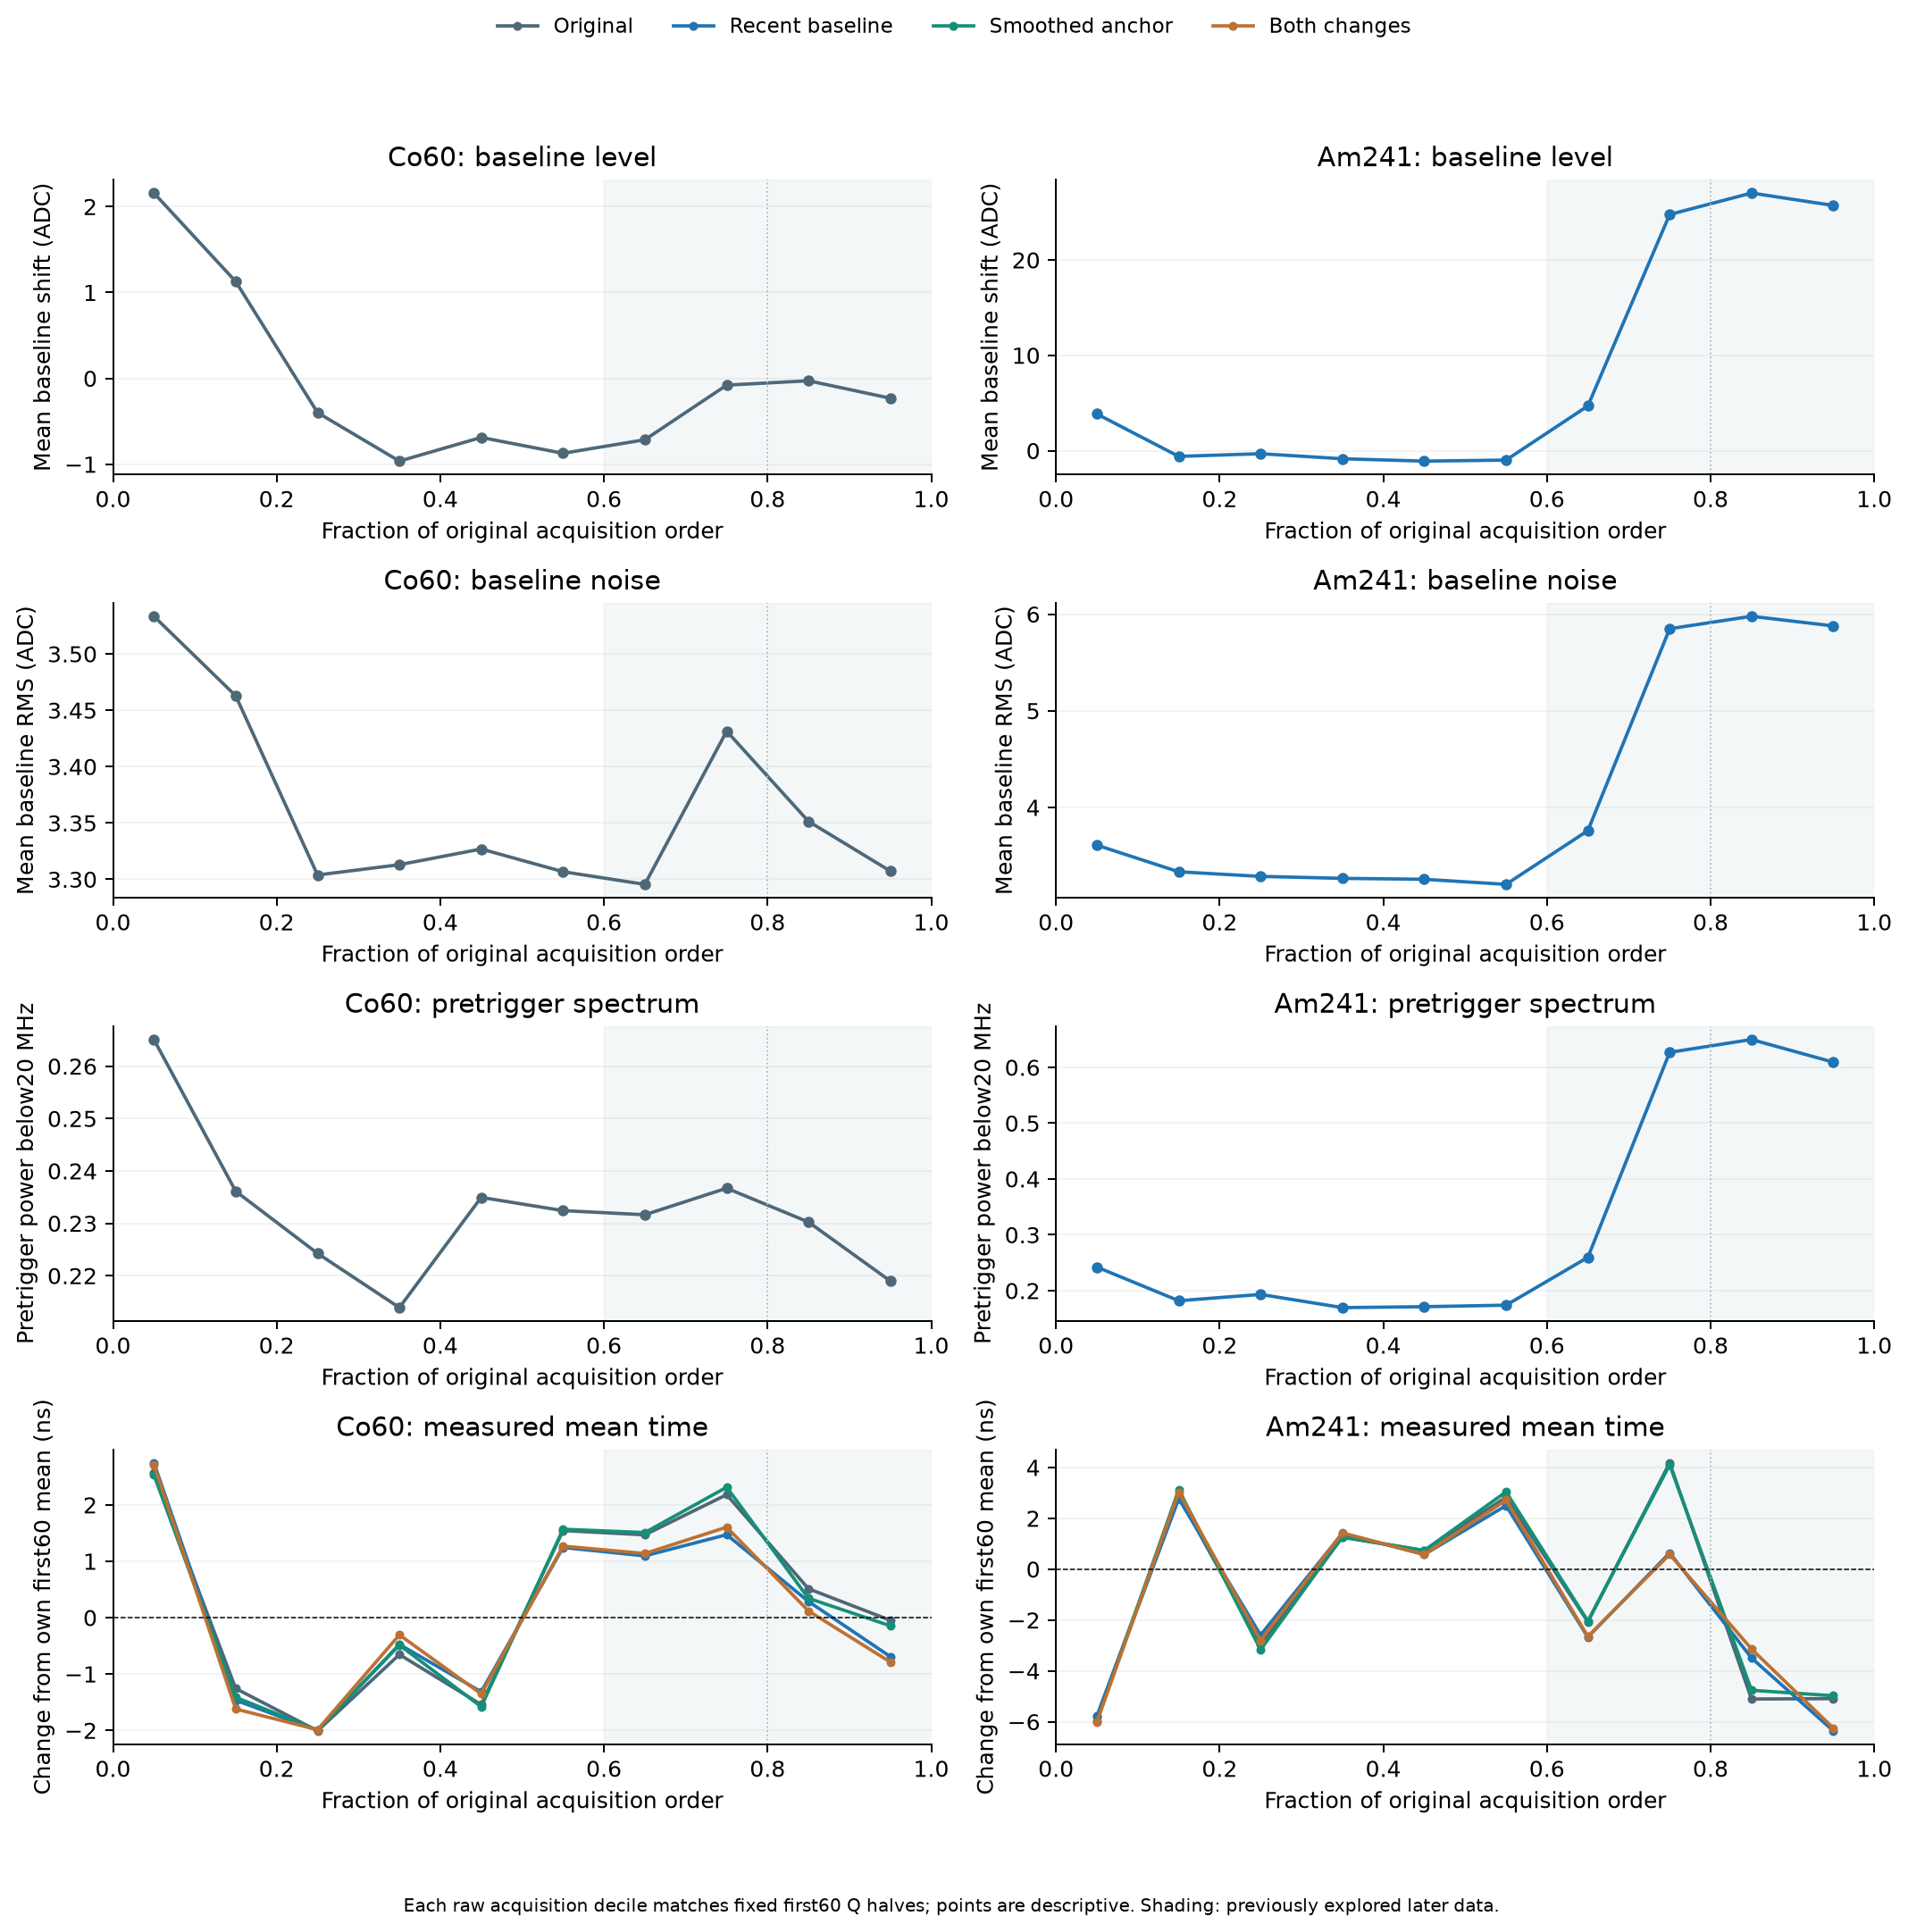

In [3]:
rows=[]
for source in ['Co60','Am241']:
    for seg in ['first60','middle20','last20']:
        r=summary[source][seg]
        rows.append([source,seg,f(r['baseline_ADC']),f(r['baseline_RMS_ADC']),f(r['low_frequency_fraction']),nums(r['F'])])
display(Markdown(table(['源','采集段','基线/ADC','RMS/ADC','低频功率比例','F50/102/202'],rows)))
display(Image(filename=str(OUT/'figures/acquisition_state_traces.png')))

## 3. 基线与定位方法的四组配对对照

- 原定义：前128样点均值作基线，原始ADC估计t₁₀。
- 近期基线：在**原整数锚点**之前[−192,−64)样点取128点均值。
- 平滑定位：对ADC作11样点中心盒平均，只用平滑波形重新求t₁₀和整数锚点。
- 两项同时改变：近期基线窗口仍固定在原锚点，不随新定位再次移动。

所有PID积分仍用原始ADC；长门−40至3000 ns、短门−40至500 ns，PCA冻结。对实测和MC同时应用相同估计方法。
这只是估计器敏感性诊断，**没有把另一种PID定义的接近程度当作Geant4物理模型已被验证**，也没有采用一个事后挑选的新定义。
95%条件区间来自512次完整母事件与原始事件块重采样，块64/128均保留；全部方法共用重采样次数，变化区间是配对计算。


|后段源|估计方法|MC−实测时间/ns|时间差区间64|QDC/时间/PCA宽度比|时间宽度比区间64|时间差变化区间/ns|宽度比变化区间|
|---|---|---|---|---|---|---|---|
|Co60|original|-0.498|[-2.576, 1.855]|0.997 / 0.940 / 1.015|[0.814, 1.206]|[0.000, 0.000]|[0.000, 0.000]|
|Co60|recent_baseline|-0.414|[-2.559, 1.972]|0.990 / 1.019 / 1.066|[0.763, 1.239]|[-0.964, 0.901]|[-0.221, 0.193]|
|Co60|smooth_anchor|-0.369|[-2.408, 1.935]|0.960 / 0.925 / 1.005|[0.805, 1.191]|[-0.053, 0.294]|[-0.071, 0.055]|
|Co60|recent_and_smooth|-0.286|[-2.482, 2.097]|0.960 / 0.998 / 1.067|[0.770, 1.249]|[-0.831, 1.032]|[-0.219, 0.210]|
|Am241|original|7.258|[0.975, 13.758]|1.058 / 0.917 / 1.096|[0.695, 1.073]|[0.000, 0.000]|[0.000, 0.000]|
|Am241|recent_baseline|7.138|[0.725, 13.565]|1.099 / 0.907 / 1.181|[0.690, 1.168]|[-2.378, 2.109]|[-0.134, 0.207]|
|Am241|smooth_anchor|7.176|[0.846, 13.789]|1.014 / 0.891 / 1.118|[0.685, 1.057]|[-0.410, 0.225]|[-0.061, 0.036]|
|Am241|recent_and_smooth|7.052|[0.650, 13.475]|1.113 / 0.925 / 1.152|[0.686, 1.185]|[-2.483, 1.959]|[-0.128, 0.214]|

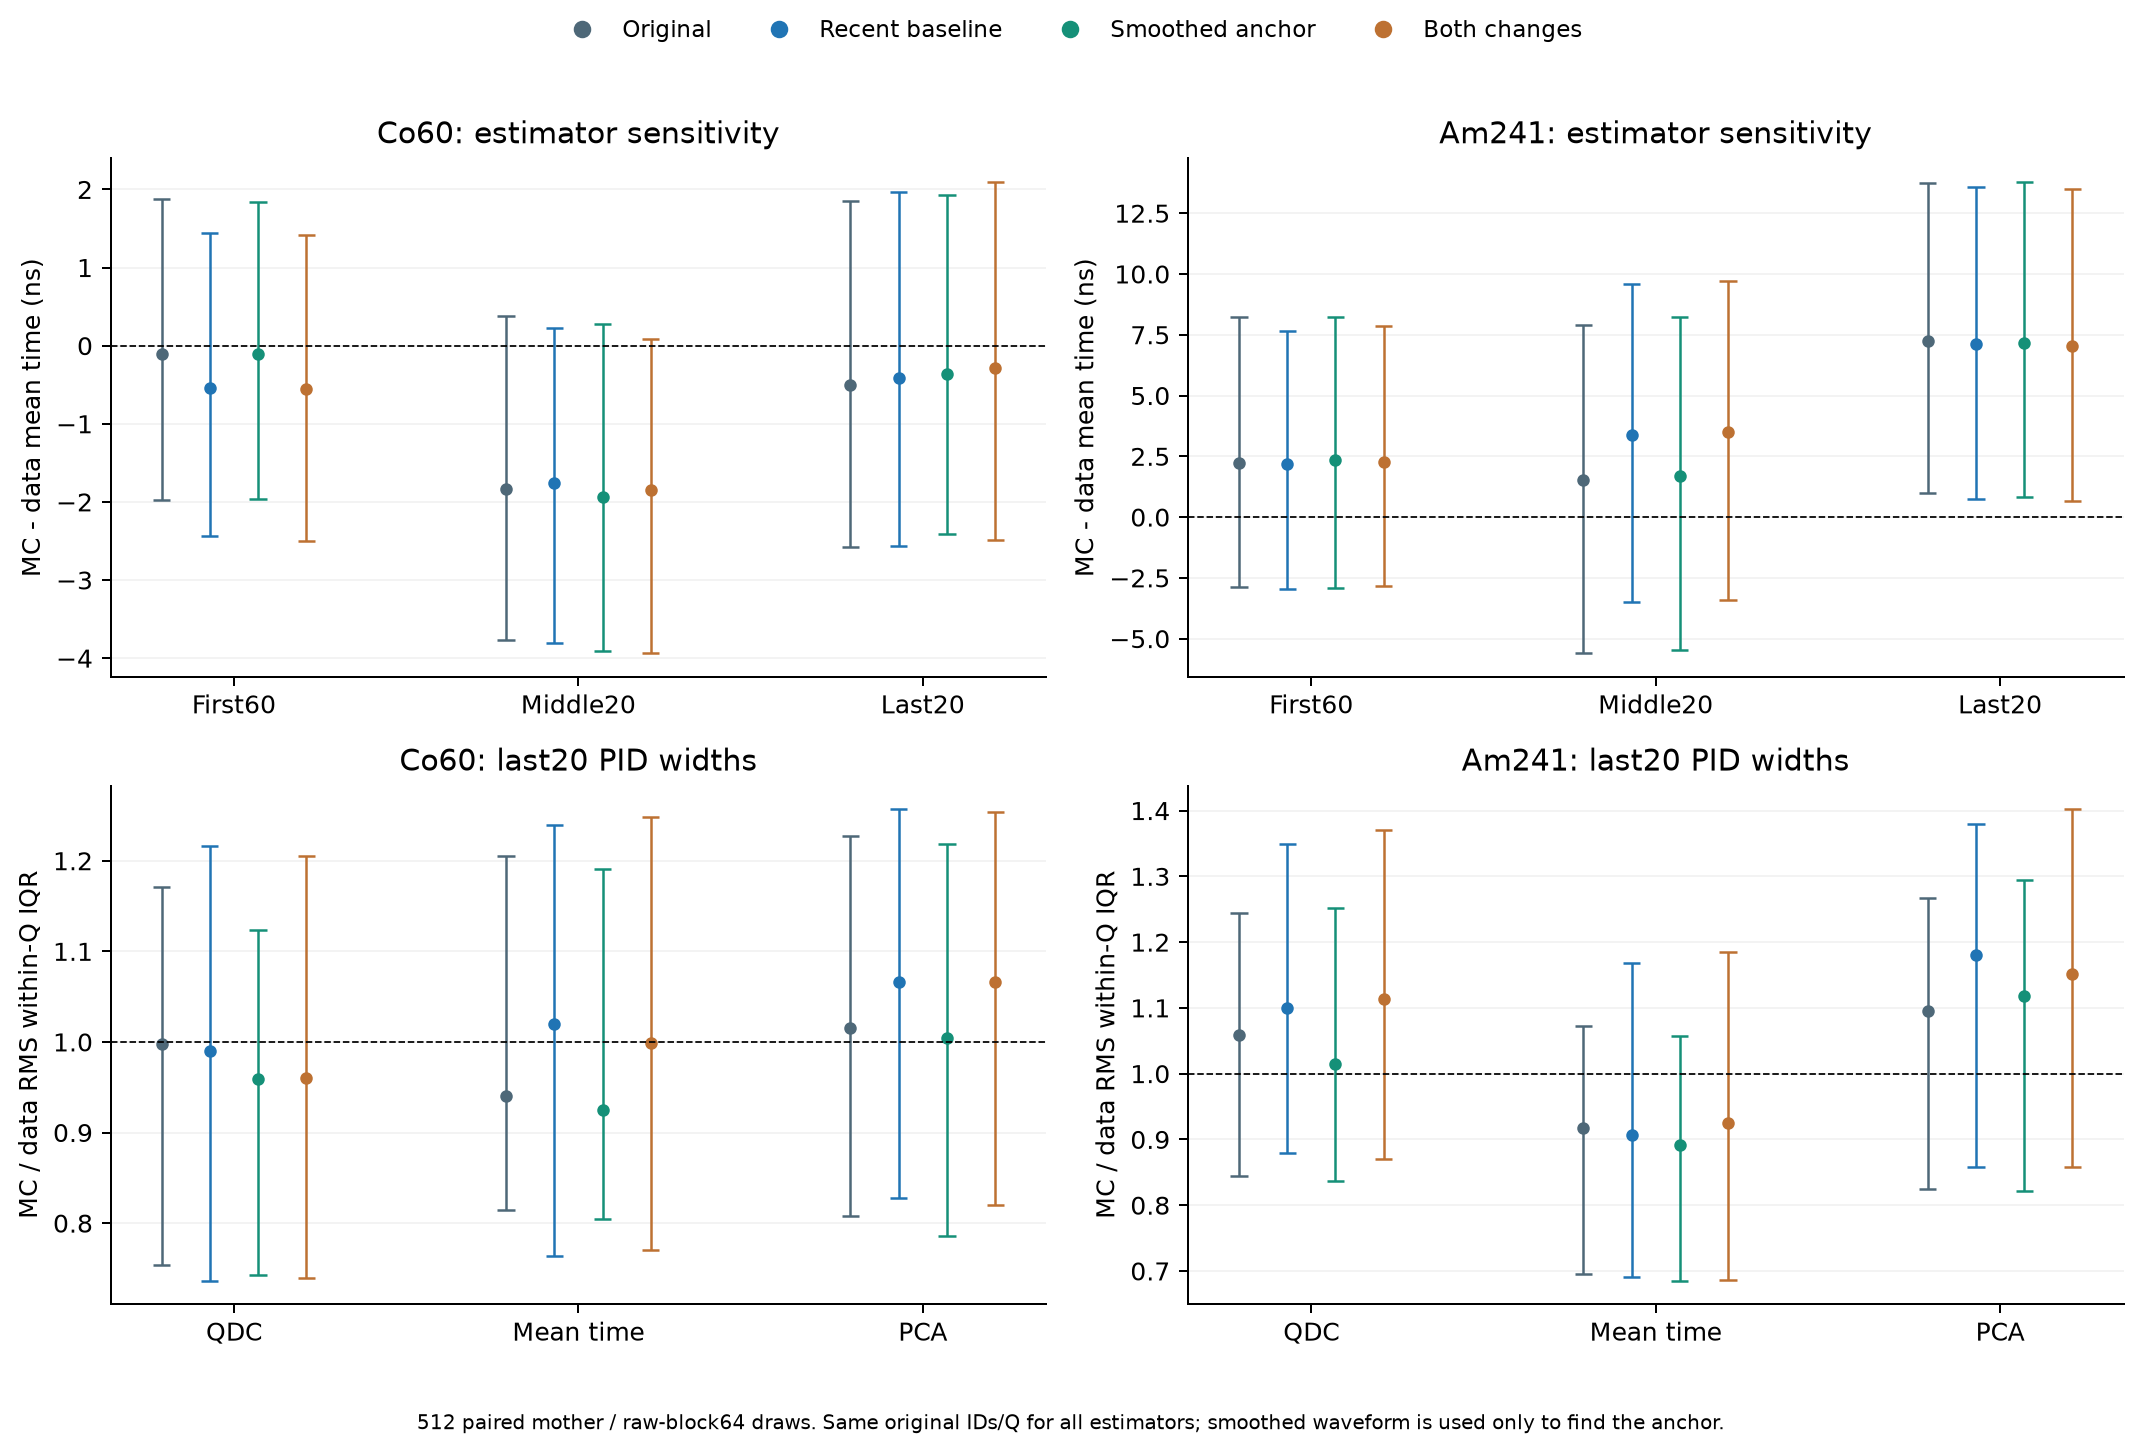

In [4]:
rows=[]
for run,source in [(3,'Co60'),(12,'Am241')]:
    for name,r in c['groups'][f'run{run}_last20']['comparisons']['identity'].items():
        u=r['uncertainty']['64']
        rows.append([source,name,f(r['mean_time_difference_ns']),ci(u['contrasts'][0]),nums(r['IQR_ratio']),
            ci(u['contrasts'][2]),ci(u['paired_change_from_original'][0]),ci(u['paired_change_from_original'][2])])
display(Markdown(table(['后段源','估计方法','MC−实测时间/ns','时间差区间64','QDC/时间/PCA宽度比','时间宽度比区间64','时间差变化区间/ns','宽度比变化区间'],rows)))
display(Image(filename=str(OUT/'figures/estimator_state_controls.png')))

Am后段四种定义的中心差仍为7.05–7.26 ns，点估计最多移动约0.21 ns；原平均时间宽度比为0.917，两项同时改变为0.925，配对变化区间包含0。
因此本轮的这两类估计敏感性没有解释原先的中心和带宽问题。这不排除其它门、基线模型或未记录读出因素。
下表另列实测段间差异，以及关闭经验残差时的MC表现，避免只看一种比较。


In [5]:
rows=[]
for run,source in [(3,'Co60'),(12,'Am241')]:
    for j,name in enumerate(p['controls']):
        r=summary[source];off=c['groups'][f'run{run}_last20']['comparisons']['no_signal_residual'][name]
        rows.append([source,name,f(r['measured_last_minus_first60_ns'][j]),ci(r['change_uncertainty']['64'][j]),
            ci(r['change_uncertainty']['128'][j]),f(off['IQR_ratio'][1])])
display(Markdown(table(['源','定义','实测后段−前段/ns','块64区间','块128区间','关闭经验残差后时间宽度比'],rows)))

|源|定义|实测后段−前段/ns|块64区间|块128区间|关闭经验残差后时间宽度比|
|---|---|---|---|---|---|
|Co60|original|0.395|[-1.130, 1.894]|[-1.410, 2.267]|0.869|
|Co60|recent_baseline|-0.134|[-1.865, 1.824]|[-2.238, 1.948]|0.798|
|Co60|smooth_anchor|0.264|[-1.254, 1.839]|[-1.523, 2.084]|0.817|
|Co60|recent_and_smooth|-0.263|[-1.999, 1.732]|[-2.345, 1.868]|0.793|
|Am241|original|-5.017|[-9.088, -0.583]|[-10.292, 0.339]|0.389|
|Am241|recent_baseline|-4.974|[-8.947, -0.944]|[-9.280, -0.566]|0.367|
|Am241|smooth_anchor|-4.820|[-8.924, -0.207]|[-10.348, 0.655]|0.372|
|Am241|recent_and_smooth|-4.773|[-8.753, -0.721]|[-9.248, -0.200]|0.369|

## 4. 前触发状态能否预测PID形状

固定四个简单模型：Q箱截距及箱内Q线性项；再分别加三项前触发状态、原始事件顺序，或两者都加。用加权普通最小二乘，不调超参数，不从结果中选择最佳模型。
只用first60训练；先以其中6个连续采集十分位做逐段留出，比较新回归模型的预测均方误差（MSE）。PCA、Q切点和Q权重目标继承并固定，所以这只是**新状态回归层的内部交叉检查**，不是全分析流程的独立验证。

模型再用完整first60拟合，应用到中/后段时只作探索性检查。支持区域同时要求：三项状态量各自在first60加权1%–99%范围内，且三维Mahalanobis距离平方不超过first60加权99%分位数。
这是预设的描述性训练范围，不保证因果可比性；所有主PID统计仍使用全套冻结事件，未按这个范围删除事件。
事件顺序模型在后段必然外推，图中展示它的外推失败，不据此修正模拟或实测波形。


|源|模型|QDC/时间/PCA交叉MSE比|各折时间MSE最小/ns²|最大/ns²|完整拟合条件数|
|---|---|---|---|---|---|
|Co60|Q|1.000 / 1.000 / 1.000|202.365|300.619|1.948|
|Co60|Q_state|0.993 / 0.970 / 0.990|198.274|339.533|6.123|
|Co60|Q_time|1.015 / 1.018 / 1.016|202.568|305.988|4.712|
|Co60|Q_state_time|1.009 / 0.980 / 1.006|202.598|301.622|6.510|
|Am241|Q|1.000 / 1.000 / 1.000|859.778|1127.316|1.872|
|Am241|Q_state|1.002 / 1.060 / 1.009|855.727|1523.649|4.641|
|Am241|Q_time|0.993 / 0.999 / 0.997|855.311|1128.443|3.212|
|Am241|Q_state_time|0.999 / 1.061 / 1.008|854.919|1522.380|4.775|

|源|段|基线/RMS/频谱各自支持比例|联合支持比例|Q+状态预测相对前段/ns|
|---|---|---|---|---|
|Co60|first60|0.980 / 0.980 / 0.980|0.944|-0.000|
|Co60|middle20|0.998 / 0.977 / 0.968|0.947|0.777|
|Co60|last20|0.993 / 0.985 / 0.984|0.962|0.232|
|Am241|first60|0.979 / 0.979 / 0.980|0.949|-0.000|
|Am241|middle20|0.813 / 0.843 / 0.827|0.665|-14.026|
|Am241|last20|0.547 / 0.712 / 0.679|0.337|-26.609|

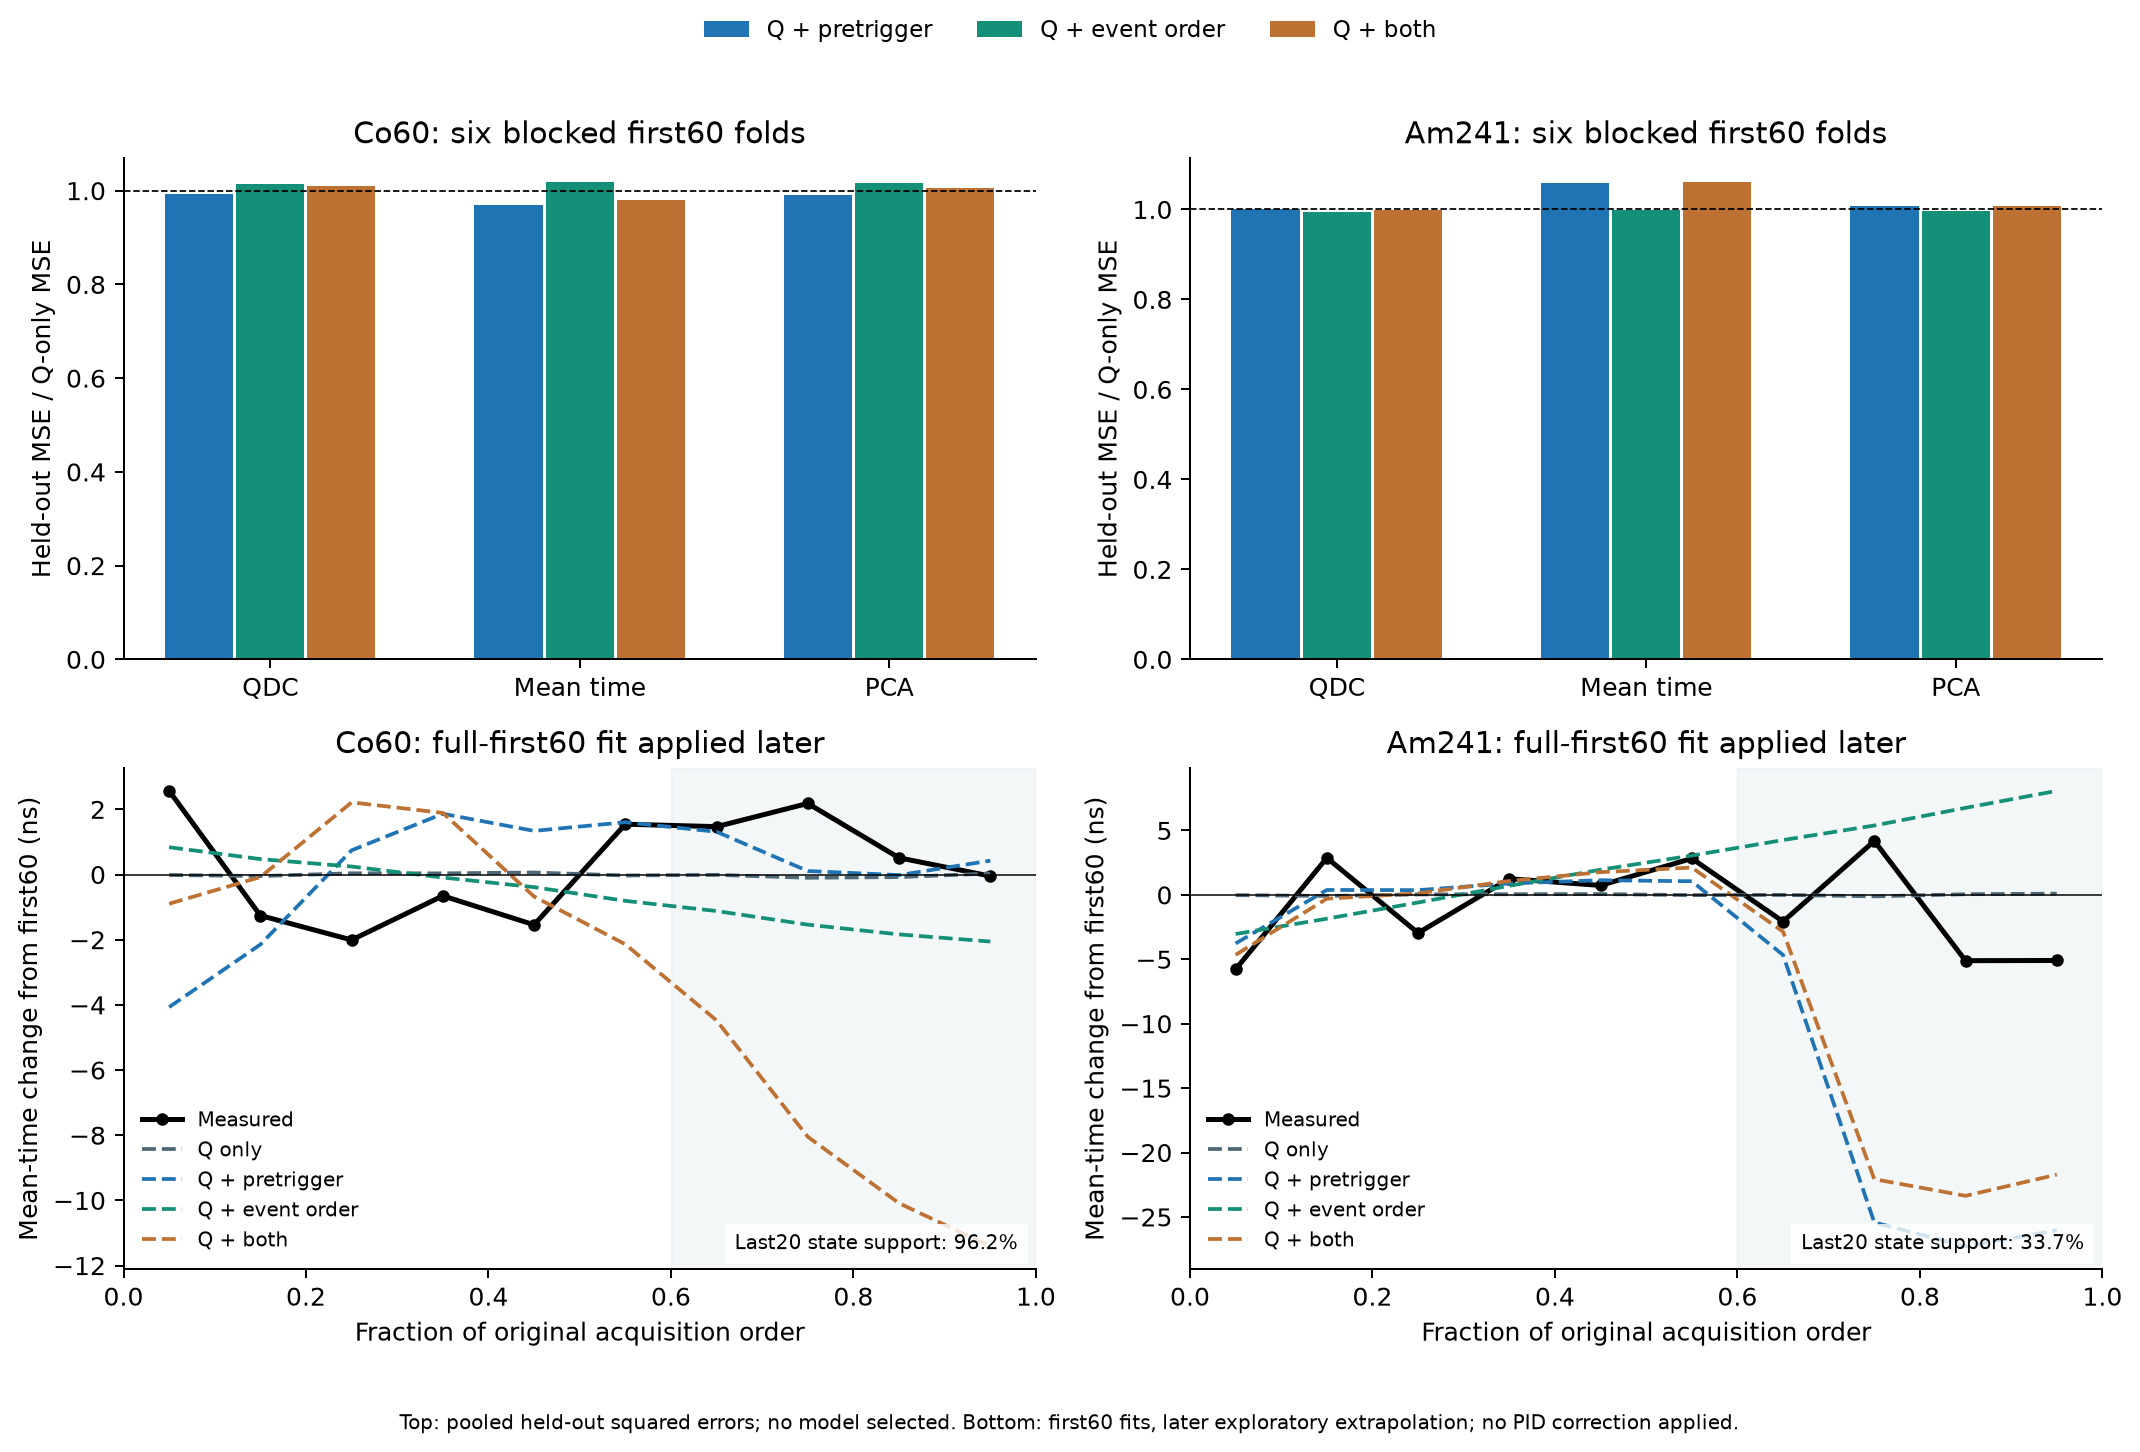

In [6]:
rows=[]
for source in ['Co60','Am241']:
    z=s['sources'][source]
    for name,v in z['CV_MSE_ratio_to_Q'].items():
        folds=[r['MSE'][1] for r in z['folds'][name]]
        rows.append([source,name,nums(v),f(1e6*min(folds)),f(1e6*max(folds)),f(z['models'][name]['condition'])])
display(Markdown(table(['源','模型','QDC/时间/PCA交叉MSE比','各折时间MSE最小/ns²','最大/ns²','完整拟合条件数'],rows)))
rows=[]
for source in ['Co60','Am241']:
    for seg in ['first60','middle20','last20']:
        r=summary[source][seg];z=s['sources'][source]['segments'][seg]
        rows.append([source,seg,nums(r['marginal_state_support_fraction']),f(r['joint_state_support_fraction']),
            f(z['predictions']['Q_state']['predicted_mean_time_change_from_first60_ns'])])
display(Markdown(table(['源','段','基线/RMS/频谱各自支持比例','联合支持比例','Q+状态预测相对前段/ns'],rows)))
display(Image(filename=str(OUT/'figures/pretrigger_state_prediction.png')))

Am加前触发状态后，首段留出MSE的平均时间项为Q-only的1.060倍，没有给出改进证据；这是一项描述性比较，不是带模型选择误差的正式显著性结论。
后段联合状态覆盖率仅约33.7%。该模型把后段时间变化预测为约−26.6 ns，而实测原定义约−5.0 ns；这种超出训练支持且偏离实测的外推不能当成温漂/读出校正。
Co状态覆盖率较高，但前触发模型的改进点估计也较小；不把这些系数解释为独立器件参数。


## 5. 时间均值变化与信号期协方差

在各原Q箱内，以Q两分目标加权，按全协方差公式精确拆成：Q半箱之间、Q半箱内各采集十分位均值之间、以及剩余单元内三项。这里的“时间份额”指第二项的对角元素占总方差比例。
有限样本的单元均值本身有噪声，因此这不是“真实漂移造成的方差比例”。另将每段原始64/128事件块整体置换512次，保留块内顺序和最后不足一块的长度，构造交换性参考；它不消除更长尺度依赖，也没有作多重比较校正。

同时保存76个40 ns长门电荷份额的完整协方差。每条份额之和为1，归一化会强制协方差矩阵的和约束并可能产生反相关，不能据此证明快慢闪烁分量的物理反相关。
50 ns盒高通的信号期协方差减去局部前触发协方差，再除以平均信号；滞后0严格复现原F50。它受到滤波器、有限窗口和对齐的共同影响，不是已经反卷积出的噪声谱或Fano因子。


|源|段|QDC/时间/PCA时间份额/%|块64参考2.5/50/97.5%分位|块128参考分位|
|---|---|---|---|---|
|Co60|first60|7.267 / 8.828 / 7.595|3.46 / 5.71 / 8.68|3.99 / 6.44 / 9.47|
|Co60|middle20|4.829 / 1.767 / 4.386|1.06 / 2.99 / 7.80|1.07 / 2.77 / 8.09|
|Co60|last20|5.838 / 4.909 / 4.497|0.71 / 2.37 / 5.71|0.76 / 2.29 / 5.99|
|Am241|first60|2.531 / 2.943 / 2.697|1.58 / 2.81 / 4.34|1.56 / 2.68 / 4.33|
|Am241|middle20|5.940 / 4.919 / 5.870|0.37 / 1.65 / 4.53|0.42 / 1.80 / 4.46|
|Am241|last20|1.754 / 0.318 / 1.114|0.35 / 1.73 / 4.26|0.49 / 1.87 / 4.62|

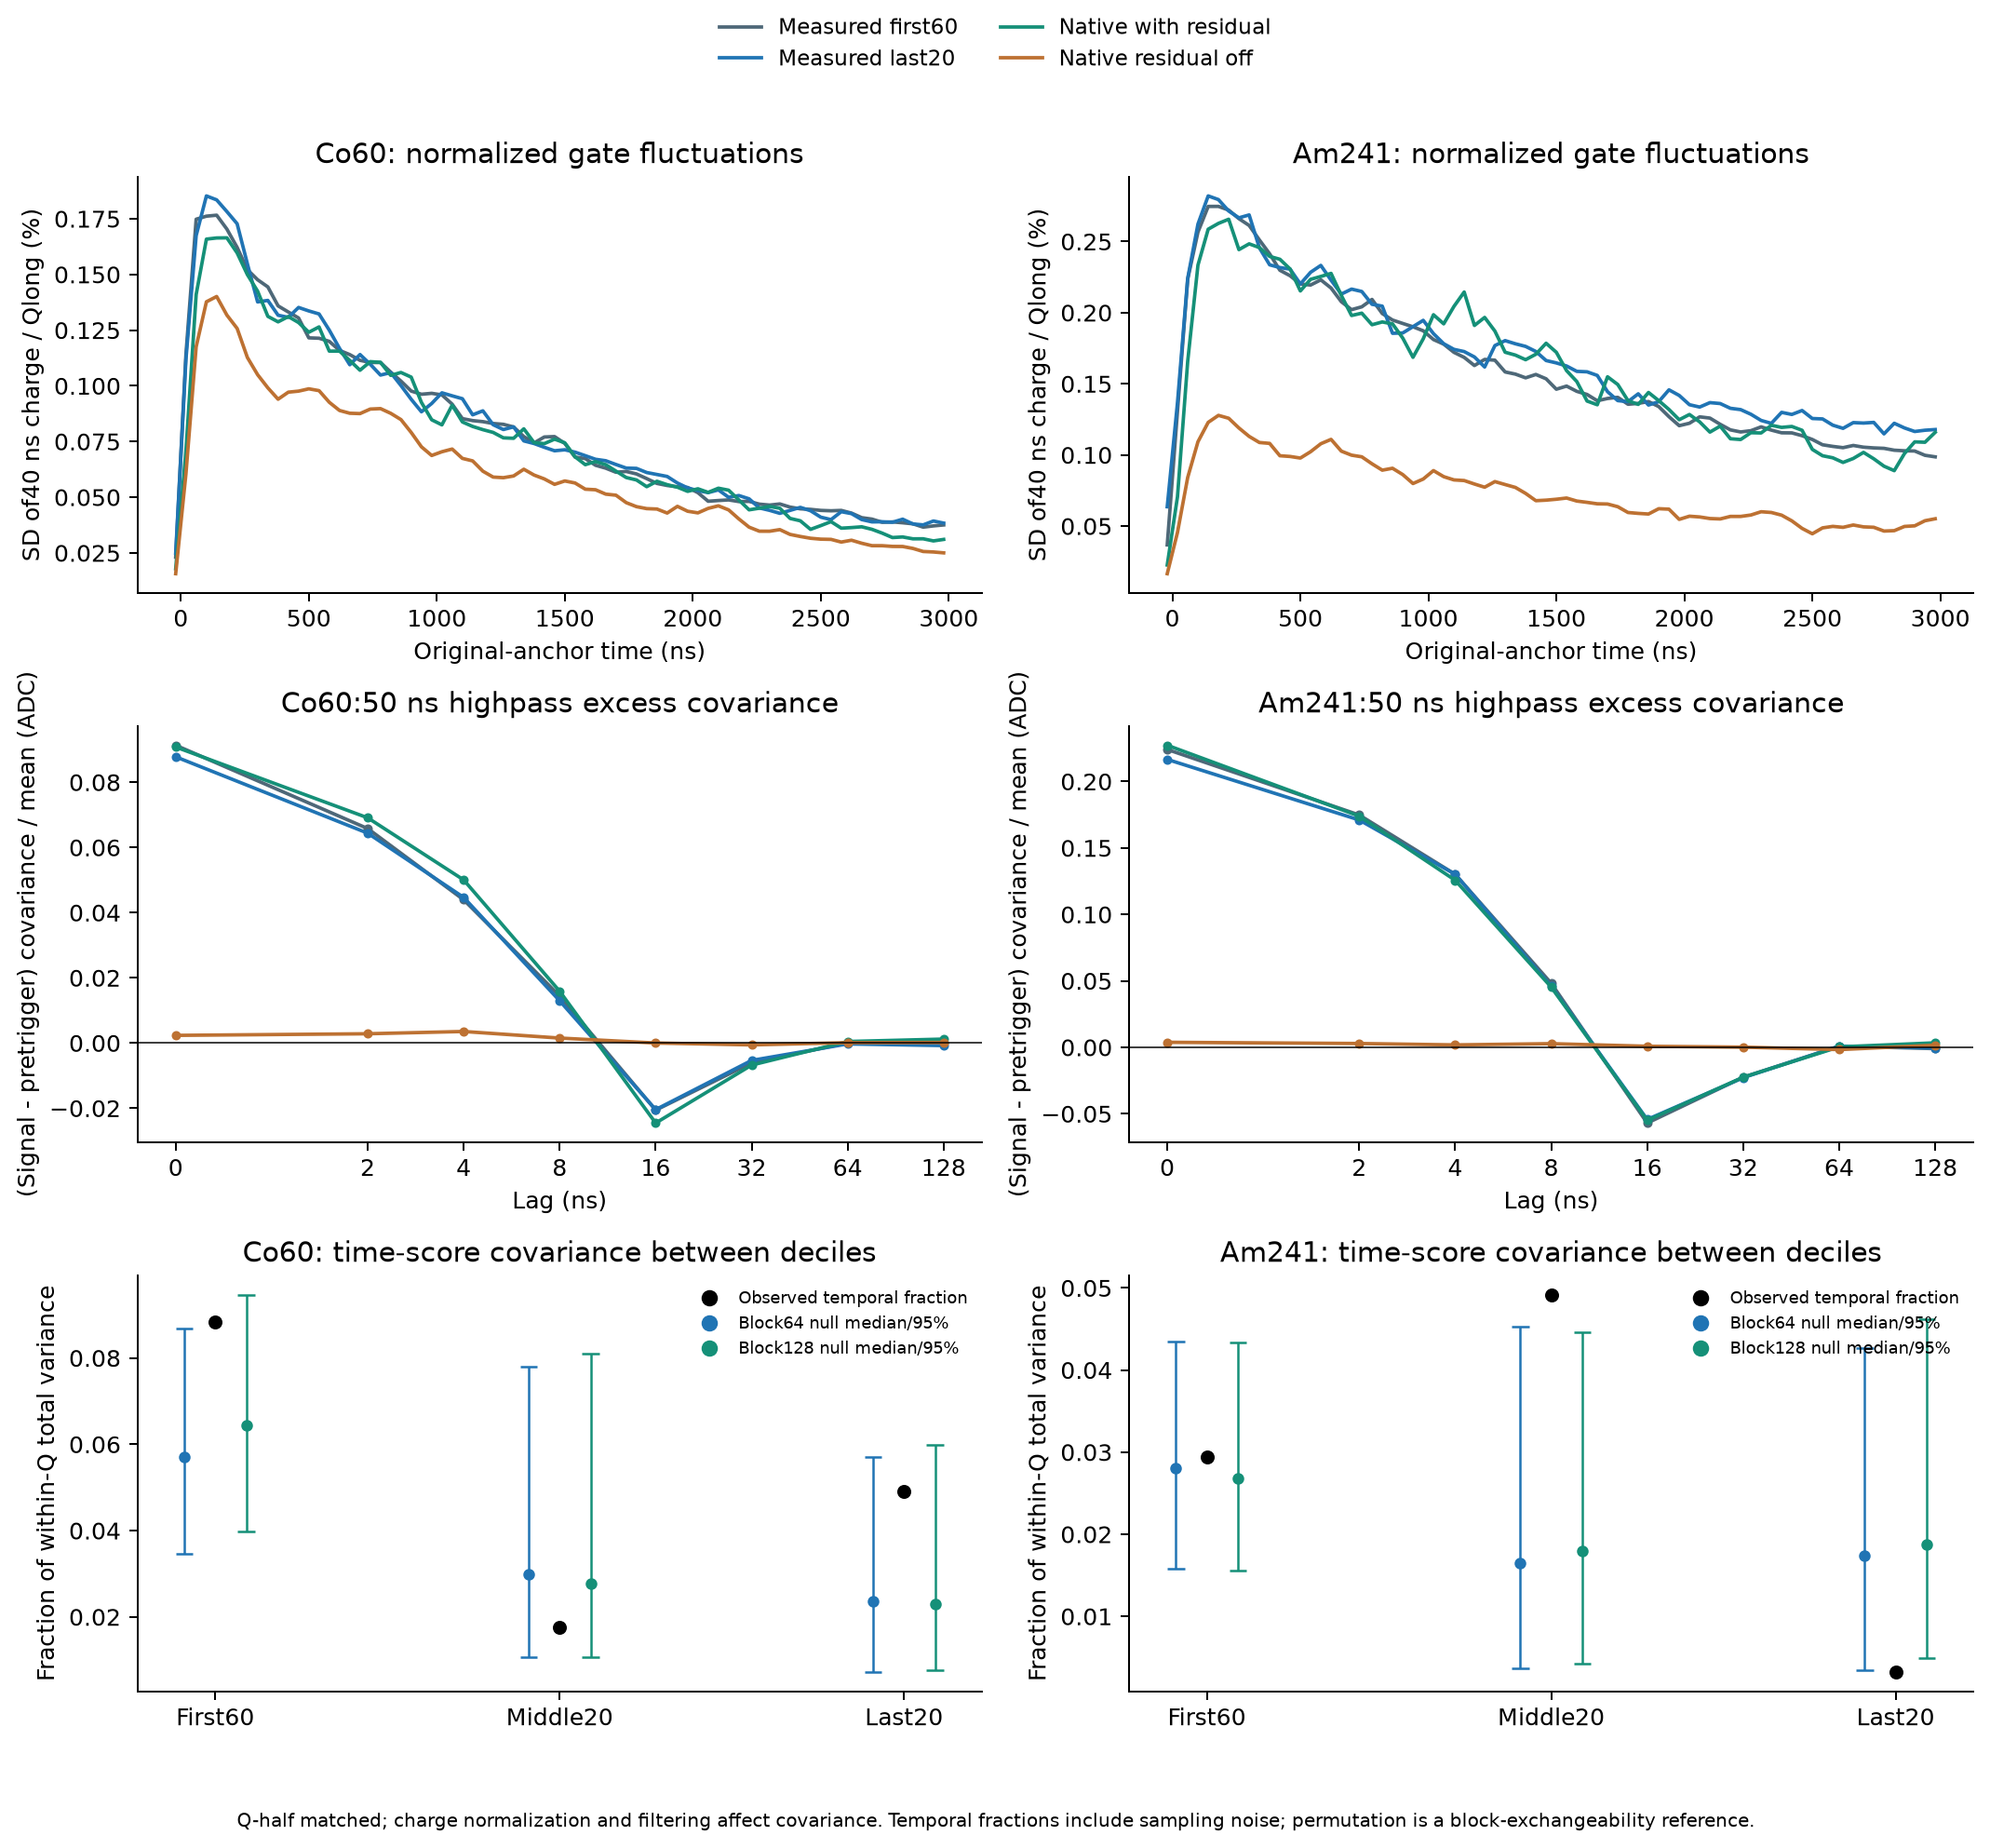

In [7]:
rows=[]
for run,source in [(3,'Co60'),(12,'Am241')]:
    for seg in ['first60','middle20','last20']:
        r=s['temporal_covariance'][f'run{run}_{seg}'];refs=[]
        for block in ['64','128']:
            v=np.array(r['permutation_reference'][block]['null_p025_p50_p975'])[:,1]
            refs.append(' / '.join(f(100*x,2) for x in v))
        rows.append([source,seg,nums([100*x for x in r['between_decile_fraction']]),*refs])
display(Markdown(table(['源','段','QDC/时间/PCA时间份额/%','块64参考2.5/50/97.5%分位','块128参考分位'],rows)))
display(Image(filename=str(OUT/'figures/signal_state_covariance.png')))

Am后段的平均时间方差中，所选采集十分位均值之间的统计份额仅约0.32%；这不能支持用该尺度的缓慢均值漂移解释大部分带宽。
Am中段对应项约4.92%，略高于两种块长的置换参考上界，是探索性迹象；不能单独据此指定一种噪声机制。
时间单元内的快速变化、方差状态变化和更长相关过程仍在剩余项里。本轮也不能把信号期的残差直接称为CsI固有涨落。

## 6. 下一步和复现

当前默认Geant4/SiPM配置及正式PID定义均保持冻结。本轮没有新增拟合的器件参数、实验真值或独立统计量。


In [8]:
display(Markdown(decision['next_work_zh']))
print('新原生重放 / 新独立母事件:',p['new_native_replay_entries'],p['new_independent_mothers'])
print('复现顺序: prepare_acquisition_state.py → analyze_acquisition_state.py controls / states → plot_acquisition_state.py')
print('笔记: jupyter/codex_0001_build_acquisition_state_notebook.py')
print('独立核验 / 冻结: simulation/verify_acquisition_state.py；随后 --archive')
print('方案:',OUT/'protocol.json')
print('配对统计:',OUT/'controls.json')
print('状态模型及协方差:',OUT/'states.json')

新原生重放 / 新独立母事件: 0 0
复现顺序: prepare_acquisition_state.py → analyze_acquisition_state.py controls / states → plot_acquisition_state.py
笔记: jupyter/codex_0001_build_acquisition_state_notebook.py
独立核验 / 冻结: simulation/verify_acquisition_state.py；随后 --archive
方案: /media/sf_works/SiPM/simulation/results/acquisition_state_20261030/protocol.json
配对统计: /media/sf_works/SiPM/simulation/results/acquisition_state_20261030/controls.json
状态模型及协方差: /media/sf_works/SiPM/simulation/results/acquisition_state_20261030/states.json


下一步优先检验**分读出状态的信号期响应模型**：保留本轮冻结结果，明确将某个后段作为新的条件校准样本，按原始事件块划分校准与内部检查，不再把它称为独立验证。先比较信号期低频整体形状起伏与短尺度残差的协方差，再同时约束均ADC、三种PID协方差和F；读出传递函数变化与快慢分量比例起伏均作为待检验候选，不能直接命名为CsI固有涨落。

候选冻结后再运行独立Geant4母事件检查模拟统计，并保留原始与条件化两套结果。现有数据无法补足装置参数、温度或实验逐事件粒子真值。